In [6]:
from config_structured_documents_graph import Settings
from dotenv import load_dotenv

load_dotenv()
settings = Settings()

In [12]:
import base64
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import END, START, StateGraph, MessagesState

vlm = ChatOpenAI(
    model="Qwen/Qwen2-VL-7B-Instruct-AWQ",  # должно совпадать с --model на сервере
    base_url="https://skillet-appealing-broken.ngrok-free.dev/v1",  # ваш текущий ngrok URL
    api_key="not-needed",
    max_tokens=2048,
)

def first_node(state: MessagesState) -> MessagesState:
    with open("test_image.png", "rb") as f:
        img_base64 = base64.b64encode(f.read()).decode("utf-8")

    message = HumanMessage(content=[
        {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{img_base64}"}},
        {"type": "text", "text": "Извлеки текст с этой страницы, сохраняя структуру, таблицы оформи как markdown"}
    ])

    response = vlm.invoke([message])

    return {"messages": [response]}

builder = StateGraph(MessagesState)
builder.add_node(first_node)
builder.add_edge(START, "first_node")
builder.add_edge("first_node", END)
graph = builder.compile()

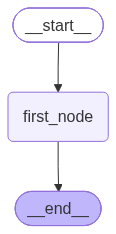

In [8]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
inv = graph.invoke({"messages": []})

for message in inv["messages"]:
    message.pretty_print()

================================== Ai Message ==================================

### Foreword

Nothing contained in any API publication is to be construed as granting any right, by implication or otherwise, for the manufacture, sale, or use of any method, apparatus, or product covered by letters patent. Neither should anything contained in the publication be construed as insuring anyone against liability for infringement of letters patent.

Shall: As used in a standard, “shall” denotes a minimum requirement in order to conform to the specification.

Should: As used in a standard, “should” denotes a recommendation or that which is advised but not required in order to conform to the specification.

This document was produced under API standardization procedures that ensure appropriate notification and participation in the developmental process and is designated as an API standard. Questions concerning the interpretation of the content of this publication or comments and questions concer

================================== Ai Message ==================================

### Foreword

Nothing contained in any API publication is to be construed as granting any right, by implication or otherwise, for the manufacture, sale, or use of any method, apparatus, or product covered by letters patent. Neither should anything contained in the publication be construed as insuring anyone against liability for infringement of letters patent.

Shall: As used in a standard, “shall” denotes a minimum requirement in order to conform to the specification.

Should: As used in a standard, “should” denotes a recommendation or that which is advised but not required in order to conform to the specification.

This document was produced under API standardization procedures that ensure appropriate notification and participation in the developmental process and is designated as an API standard. Questions concerning the interpretation of the content of this publication or comments and questions concerning the procedures under which this publication was developed should be directed in writing to the Director of Standards, American Petroleum Institute, 1220 L Street, NW, Washington, DC 20005. Requests for permission to reproduce or translate all or any part of the material published herein should also be addressed to the director.